### About the Dataset 

This data set is from kaggle and is about Spotify tracks over a range of 125 different genres. Each track has some audio features associated with it. 

The data is in CSV format which is tabular and can be loaded quickly.

Link: https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset

Credit goes to MaharshiPandya


#  EXPLORATORY DATA ANALYSIS

In [5]:
#Importing necessary libaries for the project 

# Seaborn, Numpy, Pandas, Matplotlib imports
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#Sklearn imports
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.linear_model import LinearRegression, SGDClassifier

# Stats imports
from scipy import stats

In [16]:
df = pd.read_csv('../dataset/spotify.csv')

# Reading the first 5 rows of the dataset to understand its structure and contents
df.head()



,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [ ]:
# Checking what type data type is each column in the dataset and how many non-null values are present in each column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

Why I am reducing the dataset

At first, the dataset had 114 different music genres. When i looked at this, i realized it was to complicated for the models to guess that many labels. 

If the modell just guessed the genre randomly, the chances of getting it right is very low -> 1/114 = 0.00877 (Percentage roughly 9 %)

The biggest problem is that many of these 114 genres are almost identical. 

Spotify has sub-genres like 




In [20]:
# My goal is to predict the genre of a song based on its features. The target variable is 'track_genre', and the features are all the other columns in the dataset. 
# I will be using various machine learning algorithms to classify the songs into their respective genres.
df['track_genre'].nunique()


114

In [18]:
print(sorted(df["track_genre"].unique()))


['acoustic', 'afrobeat', 'alt-rock', 'alternative', 'ambient', 'anime', 'black-metal', 'bluegrass', 'blues', 'brazil', 'breakbeat', 'british', 'cantopop', 'chicago-house', 'children', 'chill', 'classical', 'club', 'comedy', 'country', 'dance', 'dancehall', 'death-metal', 'deep-house', 'detroit-techno', 'disco', 'disney', 'drum-and-bass', 'dub', 'dubstep', 'edm', 'electro', 'electronic', 'emo', 'folk', 'forro', 'french', 'funk', 'garage', 'german', 'gospel', 'goth', 'grindcore', 'groove', 'grunge', 'guitar', 'happy', 'hard-rock', 'hardcore', 'hardstyle', 'heavy-metal', 'hip-hop', 'honky-tonk', 'house', 'idm', 'indian', 'indie', 'indie-pop', 'industrial', 'iranian', 'j-dance', 'j-idol', 'j-pop', 'j-rock', 'jazz', 'k-pop', 'kids', 'latin', 'latino', 'malay', 'mandopop', 'metal', 'metalcore', 'minimal-techno', 'mpb', 'new-age', 'opera', 'pagode', 'party', 'piano', 'pop', 'pop-film', 'power-pop', 'progressive-house', 'psych-rock', 'punk', 'punk-rock', 'r-n-b', 'reggae', 'reggaeton', 'rock',

In [19]:
# Checking if there are any duplicate rows in the dataset
# How this works is that it checks a whole row and sees if it is duplicated.
# The result shows 0, which means that there are no duplicate rows.
# But for our dataset this is not ideally important since this is a synthetic dataset from kaggle. But it is good for future projects.
print(f"Duplicate rows: {df.duplicated().sum()}")

Duplicate rows: 0


In [22]:
genres_per_track = df.groupby('track_id')['track_genre'].nunique()
print(f"Genres in more than one genre: {(genres_per_track > 1).sum()}")
print(f"Most genres for a single track: {genres_per_track.max()}")

Genres in more than one genre: 16299
Most genres for a single track: 9


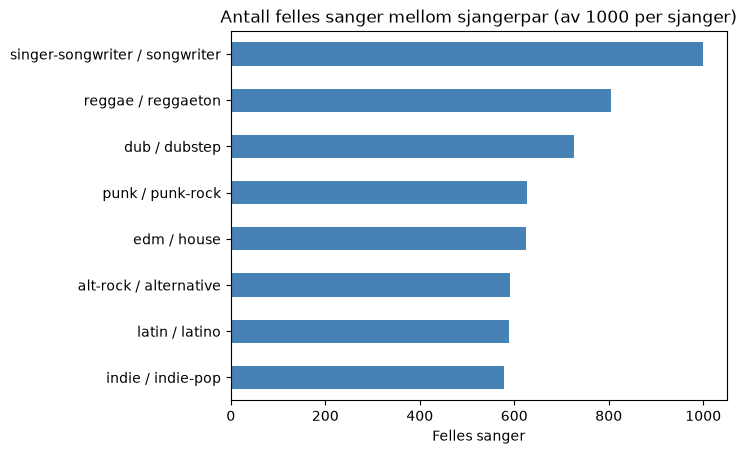

In [23]:
def shared_tracks(genre1, genre2):
    songs1 = set(df[df['track_genre'] == genre1]['track_id'])
    songs2 = set(df[df['track_genre'] == genre2]['track_id'])
    return len(songs1 & songs2)   # & = sanger som finnes i begge

pairs = [('singer-songwriter', 'songwriter'), ('reggae', 'reggaeton'),
         ('dub', 'dubstep'), ('punk', 'punk-rock'), ('edm', 'house'),
         ('alt-rock', 'alternative'), ('latin', 'latino'), ('indie', 'indie-pop')]

overlap = pd.Series({f"{a} / {b}": shared_tracks(a, b) for a, b in pairs}).sort_values()

overlap.plot(kind='barh', color='steelblue')
plt.title('Antall felles sanger mellom sjangerpar (av 1000 per sjanger)')
plt.xlabel('Felles sanger')
plt.show()